# Quantum Metal iSWAP example 2 — two pocket transmons and a flux-tunable coupler (Quantcore PDK rebuild)

**What the chip is.** Example 2 of the Qiskit Metal notebook
`docs/circuit-examples/F.Small-quantum-chips/Full-Physical-Design-of-iSWAP-Gates.ipynb` (after Phys. Rev. Research
2, 033447 (2020), Fig. 1, structure only; © IBM / Qiskit Metal contributors, Apache-2.0,
<https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/iswap2_pocket_tc.md`): two large
`TransmonPocket6` qubits (1 × 0.4 mm pads, 1.5 × 1.2 mm pockets, mm scale) 8 mm apart, with a `TunableCoupler02`
between them (two 300 µm-radius pads on a bus line that runs through a SQUID, and a flux-bias stub). Straight lines
join each qubit's inner connection pad to the coupler's bus ends; each qubit's outer pad has a 10 mm meandered line
to a launchpad, and the coupler's flux stub a line to a third launchpad. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example 2 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 16 × 6 mm centred at (0, 1) mm | the same 16 × 6 mm box (it does not fit the 7.5 mm die), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | three `LaunchpadWirebond`s 0.69 mm in from the edges | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge their pads face (south, south, east) |
| junctions | Metal junction lines (no inductance given; 10 nH assumed) | Quantcore trilayer junctions: PDK nominal for the qubits, a PDK SQUID for the coupler |
| coupler pocket | computed but never added (degenerate) | a 3.8 × 2 mm `metal:Rectangle` pocket (lead decision, option b) |
| cheese | none (the notebook never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RouteStraight`, `RouteMeander` (10 mm), a framed flux line | qcc `cpw` routes on Metal's own corner points (lengths kept; the pad leads grow with the pad rule) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options and relative positions, every route's end pins and
Metal's route corner points (route1 / route2 `RouteStraight` with their 5 µm leads and the 50 µm step between the
qubit and coupler pins; route3's 0.2 mm end lead, fillet 90 µm; route4 / route5 `RouteMeander` 10 mm, 200 µm pitch,
fillet 90 µm). All lines 10 / 6 µm (the tutorial sets `cpw_width = 0.01mm`; Metal's gap). Pin names as in the source
(route2 joins Q2's `readout` pad to the coupler, route5 Q2's `bus_03` pad to its launchpad).

**Substituted (lead decision, option b): the coupler's pocket.** `TunableCoupler02` draws metal only: Metal computes
a pocket but never adds it (and the computed one is degenerate: `draw.rectangle(0, 0, pocket_width, pocket_height)`
is a 0 × 0 box at (3, 2) mm, the arguments being width, height, x, y). Built exactly, the coupler is ground plane and
Q1 / Q2 are not coupled. It gets a `metal:Rectangle` with `subtract: true`, **3.8 × 2 mm centred on the coupler**:
Metal's `pocket_height` (2 mm), and pin to pin wide (its `pocket_width`, 3 mm, would leave the last 0.4 mm of each
bus arm, and so the coupler, shorted to the ground plane). The three coupler pins then sit on the pocket edge.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the three launchpads, the two pocket qubits, their 10 mm lines to the pads, the
coupling (the tunable coupler in its pocket and the two lines to it), the coupler's flux line, and then the whole
chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `iswap2_pocket_tc.v1.ipynb`; both save the same
`iswap2_pocket_tc.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
CPW = dict(a=10, b=6)                            # the tutorial's cpw_width = 0.01mm, Metal's cpw_gap

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 16 × 6 mm box gets the QCT frame; the three launchpads go 100 µm from the edges they face; the qubits get the PDK nominal trilayer junction and the coupler a PDK SQUID; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell).

| segment | what is placed here |
|---|---|
| 1 | the source's 16 × 6 mm box with the QCT frame |
| 2 | the three launchpads (south, south, east) |
| 3 | readout line: none on this chip |
| 4 | the two mm-scale `TransmonPocket6` qubits with the PDK junction |
| 5 | the two 10 mm meandered lines from the qubits' outer pads to their launchpads (port lines) |
| 6 | the coupling: the tunable coupler with its SQUID and its pocket, and the two straight lines to it |
| 7 | the control routing: the coupler's flux line |
| 8 | the whole chip: the sim group, the centring check, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
design does not fit the 7.5 mm die, so the box is the source's 16 × 6 mm chip. Metal centres it at (0, 1) mm, so a
Metal position (x, y) is `P(x, y)` = (8000 + x, 2000 + y) here.

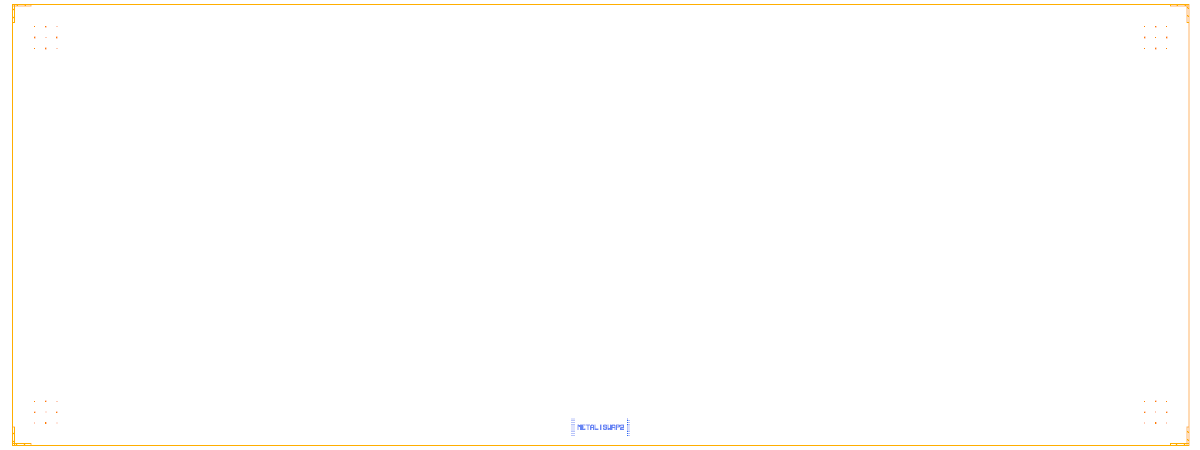

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/iswap2_pocket_tc_s1_die.png')

In [5]:
d = Designer("iswap2_pocket_tc", box=(0, 0, 16000, 6000), chip={"name_chip": "MetalISWAP2"}, live=LIVE)
X0, Y0 = 8000, 2000                              # Metal's 16 × 6 mm chip is centred at (0, 1) mm
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PP = lambda pts: [P(x, y) for x, y in pts]
layout_step(d, OUT / "iswap2_pocket_tc_s1_die.png", size=(1200, 450), width=480)

## Design 2 · Bond pads: the PDK pad rule

The tutorial's three `LaunchpadWirebond`s (0.5 × 1 mm pads, no lead) sit 0.69 mm inside the chip: `P1_C` and `P2_C`
at the ends of the two 10 mm lines with their pads pointing **south**, `P3_C` at the end of the coupler's flux line
with its pad pointing **east**. In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` =
100 µm from the die edge**: `edge="s"` / `"e"` slides each pad perpendicular to the edge it faces until it is
there, keeping its position along that edge. (`"auto"` would take the *nearest* edge, the west / north one, which
the pads do not face.) The lines are routed to the pads' ties later, so they simply get longer leads.

The table measures it on the built layout; the picture zooms on `P1_C` at the south edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

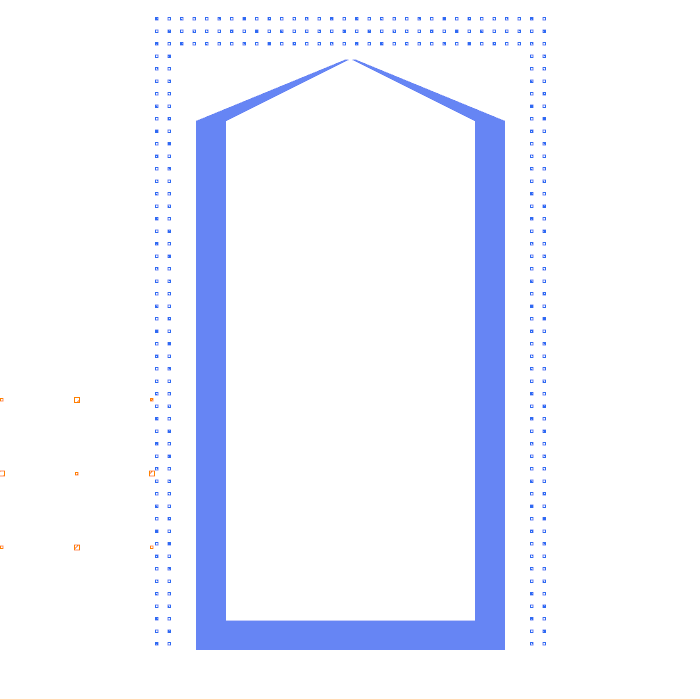

**On the chip so far:** 3 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 3 component(s) `P1_C`, `P2_C`, `P3_C`.

WindowsPath('examples/designs/metal/iswap2_pocket_tc_s2_pads.png')

In [6]:
with d.batch():
    lp = {n: d.add(n, "metal:LaunchpadWirebond", at=P(x, y), rot=r, edge=e, pad_width="0.5mm", pad_height="1mm",
                   lead_length="0um")
          for n, x, y, r, e in (("P1_C", -7000, 500, 90, "s"), ("P2_C", 7000, 500, 90, "s"),
                                ("P3_C", 3000, 3000, -180, "e"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "P1_C.tie")
layout_step(d, OUT / "iswap2_pocket_tc_s2_pads.png", box=(px - 700, 0, px + 700, 1400), size=(700, 700), width=300)

## Design 3 · Readout: none on this chip

This chip has no readout resonator and no feedline: the source's two 10 mm "readout" lines end galvanically on their
pads, so they are port lines (Design 5), and nothing needs placing before the qubits.

## Design 4 · Qubit placement: two mm-scale pocket transmons

**The qubits.** `metal:TransmonPocket6` with the tutorial's options: 1 × 0.4 mm pads, a 1.5 × 1.2 mm pocket, rotated
90°, two connection pads `bus_03` (inner side of Q1) and `readout`. Their junction is the PDK's: the tutorial gives
no target and no inductance, so each gets the PDK nominal trilayer junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0
spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); `junction=` carries L_J and C_J to the LOM
and the FEM junction port. With the mm-scale pads the estimate is f_q ≈ 4.3 GHz (the assumed 10 nH gave 3.67 GHz,
below the PDK band).

The junction cell also prepares the coupler's PDK SQUID (`SQ_PARAMS`, `SQUID`: two 0.25 × 0.6 µm junctions, 45 kΩ in
parallel), which Design 6 uses. The qubits sit 4 mm either side of the box centre.

qubits: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0} | coupler: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['bus_03', 'readout', 'squid_a', 'squid_b']


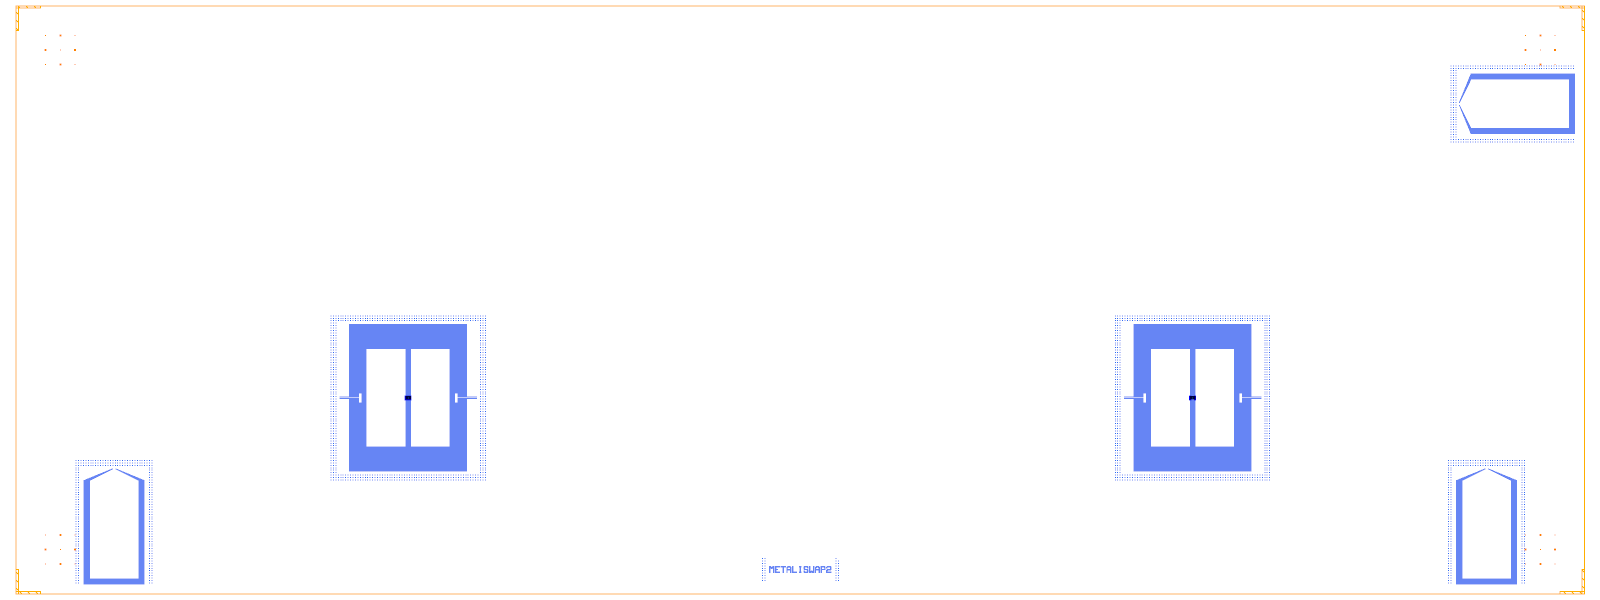

**On the chip so far:** 3 pads · 2 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `Q1`, `Q2`.

WindowsPath('examples/designs/metal/iswap2_pocket_tc_s4_qubits.png')

In [7]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
# flux-tunable qubits / couplers: a Quantcore SQUID of two junctions, R_n 45 kΩ in parallel (L_J 6.73 nH at zero
# flux, C_J 15 fF); SQ_PARAMS = {"junction_type": "Quantcore Squid", "junction_params": {"lj_nH": 6.73}}
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)
print("qubits:", JJ_PARAMS, JUNCTION, "| coupler:", SQ_PARAMS, SQUID)
with d.batch():
    pads = {"bus_03": {"loc_W": 0, "loc_H": -1, "pad_width": "100um", "pad_gap": "50um"},
            "readout": {"loc_W": 0, "loc_H": 1, "pad_width": "100um", "pad_gap": "50um"}}
    q = {n: d.add(n, "metal:TransmonPocket6", at=P(x, 0), rot=90, junction=JUNCTION, **JJ_PARAMS, pad_width="1mm",
                  pad_height="0.4mm", pocket_width="1.5mm", pocket_height="1.2mm", pad_gap="0.05mm",
                  connection_pads=pads)
         for n, x in (("Q1", -4000), ("Q2", 4000))}
print("Q1 ports:", sorted(q["Q1"].ports))
layout_step(d, OUT / "iswap2_pocket_tc_s4_qubits.png", size=(1600, 600), width=560)

## Design 5 · Readout: the two 10 mm lines to the launchpads

Each qubit's outer pad gets a 10 / 6 µm CPW to its launchpad on Metal's own corner points (`ROUTE4`; route5 is its
mirror), so the paths and lengths are the tutorial's:
- **route4 / route5:** the 10 mm meandered lines from each qubit's outer pad to its launchpad (Metal's
  `RouteMeander` corner points, 200 µm pitch, fillet 90 µm). The source's "readout" lines end galvanically on the
  pads: they are port lines, not resonators.

The pad rule moved `P1_C` / `P2_C` to the south edge (Design 2), so the last straight of each line is longer than in
the source (printed lengths, Design 8).

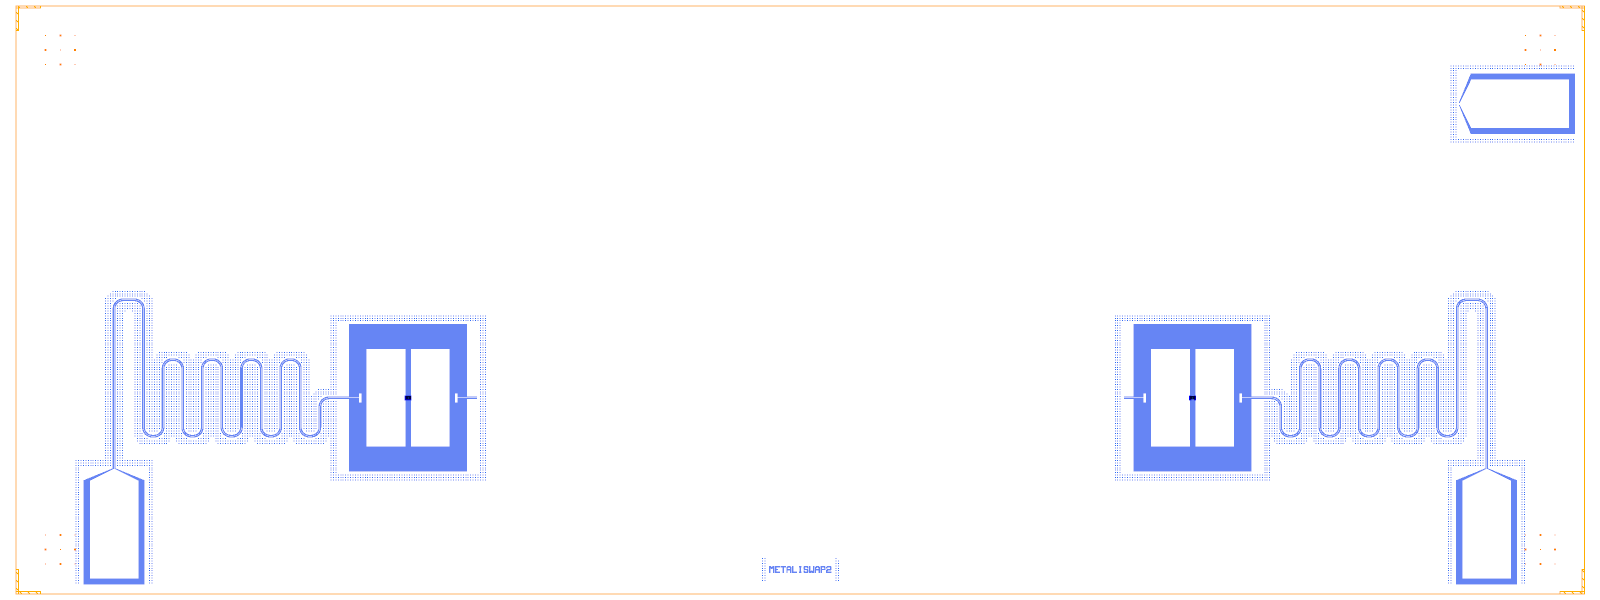

**On the chip so far:** 3 pads · 2 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 2 route(s) `route4`, `route5`.

WindowsPath('examples/designs/metal/iswap2_pocket_tc_s5_lines.png')

In [8]:
# Metal's corner points (µm, Metal frame) of the RouteMeander route4 (route5 is its mirror)
ROUTE4 = [[-4900.0, 0.0], [-4900.0, -389.51], [-5100.0, -389.51], [-5100.0, 389.51], [-5300.0, 389.51], [-5300.0, -389.51], [-5500.0, -389.51], [-5500.0, 389.51], [-5700.0, 389.51], [-5700.0, -389.51], [-5900.0, -389.51], [-5900.0, 389.51], [-6100.0, 389.51], [-6100.0, -389.51], [-6300.0, -389.51], [-6300.0, 389.51], [-6500.0, 389.51], [-6500.0, -389.51], [-6700.0, -389.51], [-6700.0, 1000.0], [-7000.0, 1000.0]]
with d.batch():
    # 10 mm meandered lines to the launchpads (Metal's corner points, fillet 90 µm)
    d.route("route4", q["Q1"].readout, lp["P1_C"].tie, r=90, nodes=PP(ROUTE4), **CPW)
    d.route("route5", q["Q2"].bus_03, lp["P2_C"].tie, r=90, nodes=PP([(-x, y) for x, y in ROUTE4]), **CPW)
layout_step(d, OUT / "iswap2_pocket_tc_s5_lines.png", size=(1600, 600), width=560)

## Design 6 · Coupling: the tunable coupler, its pocket and the two lines to it

**The coupler.** `metal:TunableCoupler02` (a series SQUID in a bus line, two 300 µm pads, a flux stub `fbl`) gets a
PDK SQUID: two 0.25 × 0.6 µm junctions, 45 kΩ in parallel, L_J 6.73 nH at zero flux. Its **pocket** (a
`metal:Rectangle` with `subtract: true`, 3.8 × 2 mm) is the substitution explained above: without it the coupler is
ground plane.

**route1 / route2** join each qubit's inner pad to a coupler bus end (Metal `RouteStraight`: 5 µm leads, a straight
line across the 50 µm pin step). The second picture zooms on `Q1` and the coupler.

TC ports: ['fbl', 'pin1', 'pin2', 'squid_a', 'squid_b']


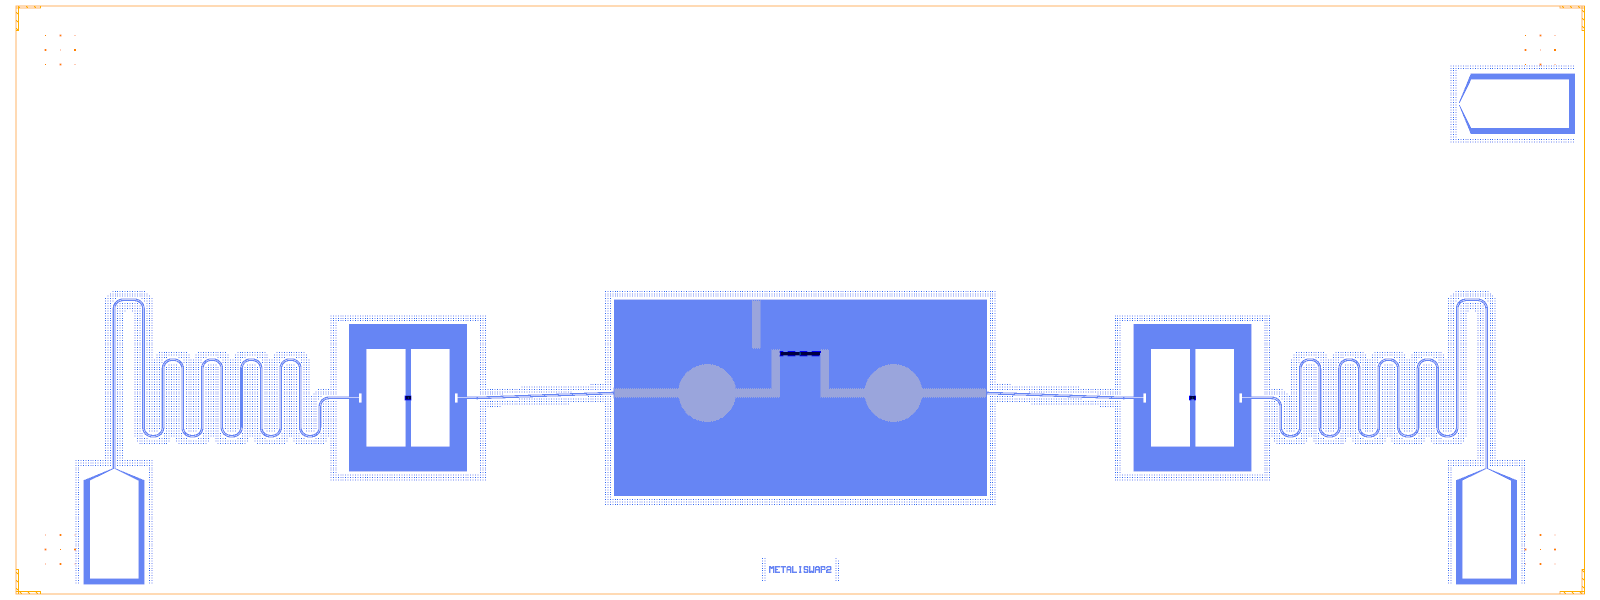

**On the chip so far:** 3 pads · 2 qubits · 2 other components · 4 routes · 0 declared couplings. **This step added** 2 component(s) `TC`, `TC_pocket` and 2 route(s) `route1`, `route2`.

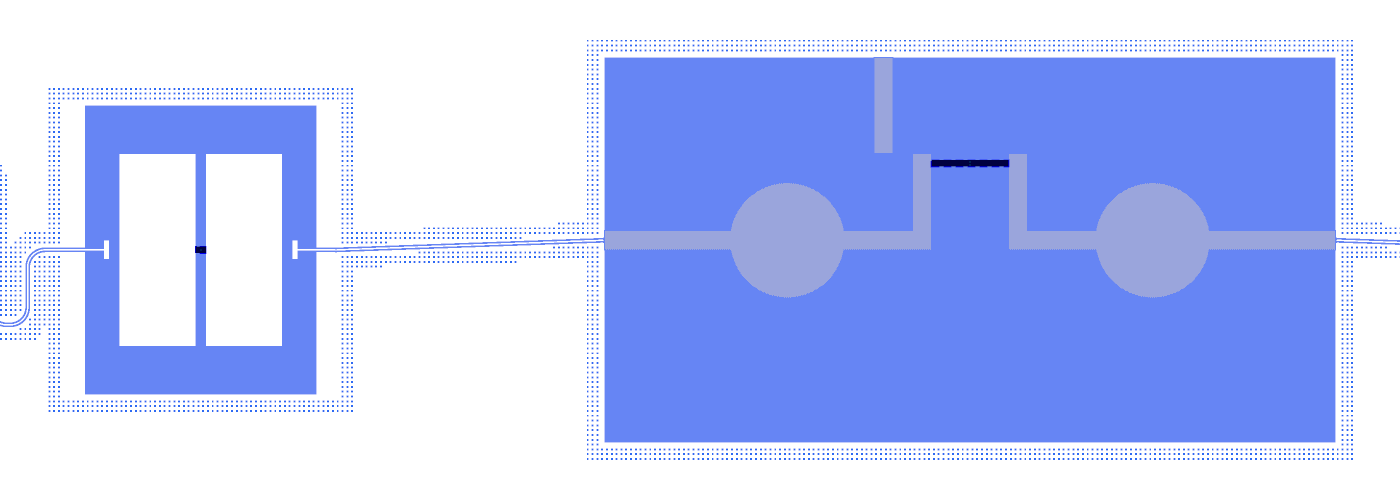

WindowsPath('examples/designs/metal/iswap2_pocket_tc_step_parts.png')

In [9]:
with d.batch():
    tc = d.add("TC", "metal:TunableCoupler02", at=P(0, 0), junction=SQUID, **SQ_PARAMS)
    # the pocket Metal never adds: pocket_height 2 mm, pin to pin (3.8 mm) wide, centred on the coupler
    d.add("TC_pocket", "metal:Rectangle", at=P(0, 0), width=3800, height=2000, subtract=True)
    # qubit ↔ coupler (Metal RouteStraight: 5 µm leads, a straight line across the 50 µm pin step)
    d.route("route1", q["Q1"].bus_03, tc.pin2, r=1, nodes=PP([(-3295, 0), (-1905, 50)]), **CPW)
    d.route("route2", q["Q2"].readout, tc.pin1, r=1, nodes=PP([(3295, 0), (1905, 50)]), **CPW)
print("TC ports:", sorted(tc.ports))
layout_step(d, OUT / "iswap2_pocket_tc_s6_coupler.png", size=(1600, 600), width=560)
snap(d, OUT / "iswap2_pocket_tc_step_parts.png", box=P(-5000, -1300) + P(2200, 1300), size=(1400, 500), width=560)

## Design 7 · Routing: the coupler's flux line

`route3` carries the coupler's flux bias from `P3_C` (east edge) to the stub `fbl`: a long lead west, then down to the
stub (Metal's corner points `ROUTE3`, fillet 90 µm). The pad moved to the east edge, so its first straight is longer
than in the source.

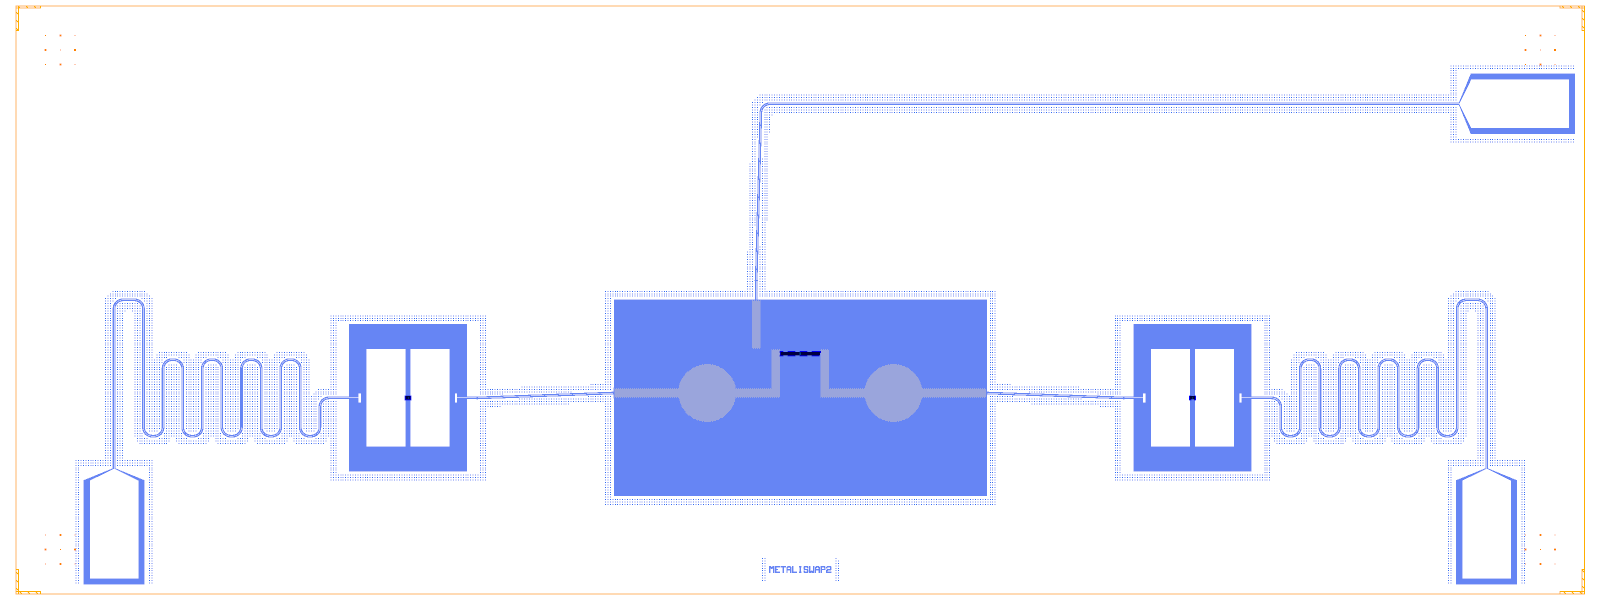

**On the chip so far:** 3 pads · 2 qubits · 2 other components · 5 routes · 0 declared couplings. **This step added** 1 route(s) `route3`.

WindowsPath('examples/designs/metal/iswap2_pocket_tc_s7_flux_line.png')

In [10]:
ROUTE3 = [[-400.0, 3000.0], [-450.0, 1200.0]]
with d.batch():
    # coupler flux bias (lead west, then down to the stub; fillet 90 µm)
    d.route("route3", lp["P3_C"].tie, tc.fbl, r=90, nodes=PP(ROUTE3), **CPW)
layout_step(d, OUT / "iswap2_pocket_tc_s7_flux_line.png", size=(1600, 600), width=560)

## Design 8 · The whole chip: the sim group, the centring check, save

**Sim group** `Q1_TC_Q2` names the FEM box: both qubits, the coupler with its pocket and the two lines between them.

**Centring.** The PDK wants the chip content centred in the die. Here the source's arrangement already fills its 16 × 6 mm box:
Q1 and Q2 sit symmetrically about the coupler at the box centre in x, and the circuit between the pads (the qubits,
the coupler and the lines, the flux line along the top) is centred in y as well. What is off-centre is the box of
*everything*, pads included: the pad rule put P1_C / P2_C on the south edge and P3_C on the east edge, so that box
leans south-east. `center_in_die` measures that box; a pad slides back to its edge after the shift, so a shift
here would only move the circuit off-centre and push P1_C and P3_C into the frame's corner marker areas. The cell
measures both offsets and tries `center_in_die` on a copy to show it (`frame_keepout` warnings); the design keeps
the source's placement.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the routes were added in another order here), so `git diff` stays empty.

content centre − die centre (µm): {'everything': (296, -296), 'without the pads': (0, 0)}


**Same design as before:** `examples/designs/metal/iswap2_pocket_tc.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

center_in_die on a copy: shift (-296.0, 296.0) µm → {'frame_keepout': 2}
<Designer iswap2_pocket_tc: 7 instances, 5 routes, live=False> → examples\designs\metal\iswap2_pocket_tc.json
route lengths (µm): {'route4': 11220.0, 'route5': 11220.0, 'route1': 1400.9, 'route2': 1400.9, 'route3': 9084.5}


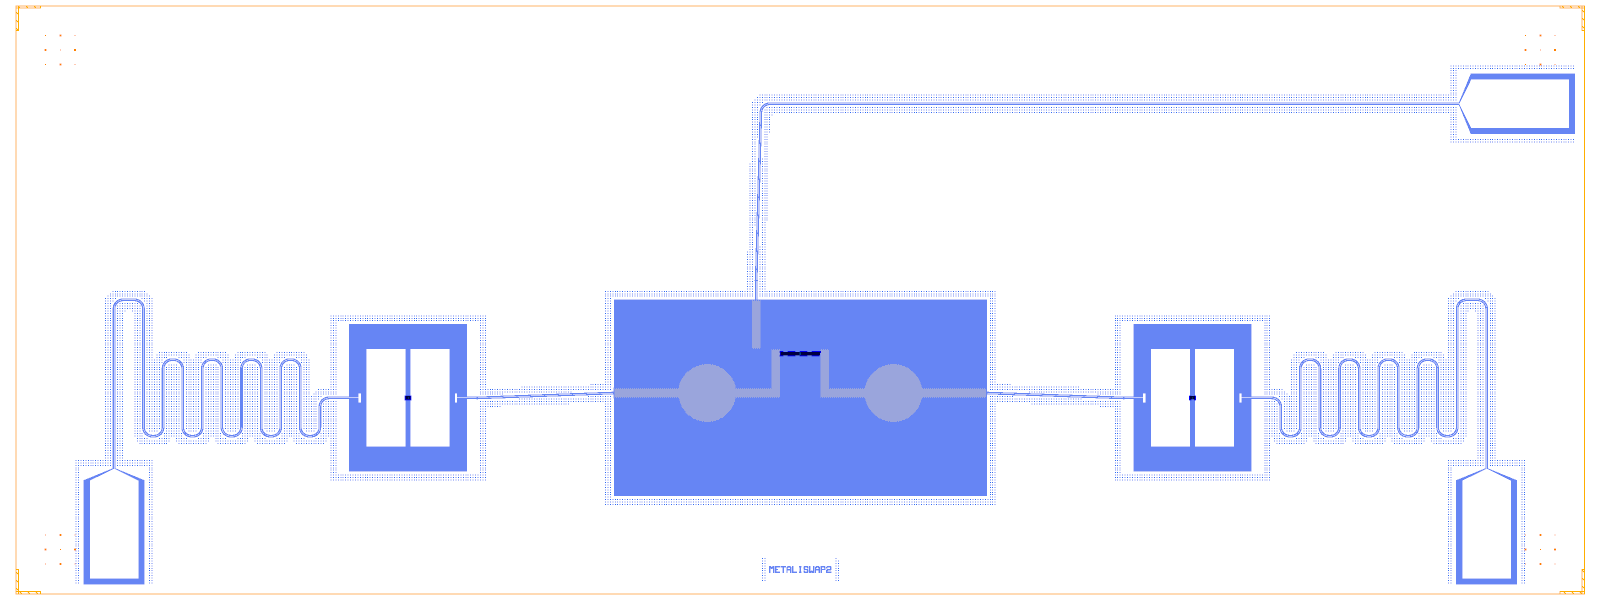

**On the chip so far:** 3 pads · 2 qubits · 2 other components · 5 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/iswap2_pocket_tc_step_routes.png')

In [11]:
# FEM box: both qubits, the coupler (with its pocket) and the two lines between them
d.sim_group("Q1_TC_Q2", ["Q1", "TC", "TC_pocket", "Q2", "route1", "route2"], margin_um=200, analyses=["q3d_cmatrix"])
from collections import Counter
from kqcircuits.pya_resolver import pya
from quantcore_circuits.assembly.sidecar import sidecar_dict
from _common import _pad_instances


def centre_offsets(d):
    """Content centre − die centre (µm): of everything placed, and of the circuit without the bond pads."""
    side, pads = sidecar_dict(rebuild(d), overlays=False), set(_pad_instances(d))
    x0, y0, x1, y1 = d.design.chip.box
    out = {}
    for label, skip in (("everything", set()), ("without the pads", pads)):
        box = pya.DBox()
        for n, inst in side["instances"].items():
            if inst.get("bbox") and n not in skip:
                box += pya.DBox(*inst["bbox"])
        for route in side["routes"].values():
            for x, y in route.get("polyline") or []:
                box += pya.DPoint(x, y)
        out[label] = (round(box.center().x - (x0 + x1) / 2), round(box.center().y - (y0 + y1) / 2))
    return out


print("content centre − die centre (µm):", centre_offsets(d))
DESIGN, same = save_design(d, OUT / "iswap2_pocket_tc.json")
display(Markdown(same))
trial = design_copy(DESIGN, "_centred")          # what center_in_die would do, on a copy
print("center_in_die on a copy: shift", center_in_die(trial), "µm →",
      dict(Counter(i.rule for i in (rebuild(trial) and trial.drc()).issues if i.rule == "frame_keepout")) or "no frame warnings")
TX, TY = d.data["instances"]["TC"]["place"]["at"]
P = lambda x, y: (TX + x, TY + y)                # Metal µm → Designer µm (TC is Metal's (0, 0))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "iswap2_pocket_tc_step_routes.png", size=(1600, 600), width=560)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; six `dangling_port` warnings (`squid_a` / `squid_b` of Q1, Q2 and TC: the junction
attachment points, drawn by the cells); one `overlap`, the coupler and its own pocket, by design. **No PDK design
warnings:** the three pads are at 100 µm (`pad_edge`), the nominal junctions are 45 kΩ and the coupler's PDK SQUID
(two 90 kΩ junctions) is 45 kΩ in parallel, inside the 40–50 kΩ window (`pdk_rn` checks the device), and there are no
targets (`pdk_fq`).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: `TransmonPocket6` → two floating pads (`island1` / `island2`) with
the junction, a node per connection pad; `TunableCoupler02` on its pocket → two floating pads with the SQUID between
them and the bus (`pin1`–`pin2`) as one node coupled to both pads (rough; the drawn coupler is a series SQUID, see
LOM 1), the flux stub as a control. route1 / route2 join the qubits' inner pads to the bus; route4 / route5 are
lines from the outer pads to the 50 Ω launchpads (port lines, not resonators); route3 carries the coupler's flux
bias.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "TC."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its 10 mm line to the launchpad (κ to the port), the coupler alone, then Q1–TC–Q2 (static ZZ).
From the v1 run:

- Q1 / Q2: with the PDK junction ≈ 4.3 GHz (mm-scale pads; the assumed 10 nH gave 3.67 GHz), small anharmonicity,
  κ into the 50 Ω launchpad through the 10 mm line.
- TC alone: its SQUID mode at zero flux (≈ 5.3 GHz estimated).
- **Q1–TC–Q2: QuCat fails** (`KeyError: 'ComplexInfinity'`, printed below). The `TunableCoupler02` LOM model joins
  `pin1` and `pin2` into one bus node coupled equally to both floating pads: a balanced bridge, so the SQUID mode is
  exactly decoupled and the symbolic solve divides by zero. Drawn, the coupler is a SQUID *in series* in the line
  (`pin2` – left arm and pad – SQUID – right pad and arm – `pin1`, zoom in Fab 2), which is what the FEM job sees.
  Request for lom (a series-SQUID model); until then there is no coupled result.

In [ ]:
single = simulate_groups(d, {"Q1+route4": ["Q1", "route4", "P1_C"], "Q2+route5": ["Q2", "route5", "P2_C"],
                             "TC": ["TC"]})
for g, r in single.items():
    display(Markdown(f"**{g}:**\n\n" + modes_md(r)))
display(Markdown(groups_md(single)))
try:   # fails with the current TunableCoupler02 model (see the markdown above; for lom)
    coupled = simulate_groups(d, {"Q1+TC+Q2": ["Q1", "route1", "TC", "route2", "Q2"]}, max_modes=3)
    display(Markdown("**Q1–TC–Q2, QuCat normal modes:**\n\n" + modes_md(coupled["Q1+TC+Q2"])))
    display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))
except Exception as e:
    print("Q1+TC+Q2: QuCat failed:", type(e).__name__, str(e)[:120])

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits; filled markers
are the QuTiP dressed values), (b) the dispersive shifts (none here: the lines are ports, not resonators). From the v1
run the two qubits sit on the same frequency (4.22 GHz dressed) and the coupler at 5.15 GHz; the coupled Q1–TC–Q2
group is missing (QuCat fails, LOM 1).

In [ ]:
plot_lom(single, OUT / "iswap2_pocket_tc_lom.png", title="iswap2: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step. Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here Q1's pad height, 0.4 → 0.3 mm — and re-run the LOM of Q1 with its line. Smaller pads mean a smaller C_Σ: the
charging energy grows, so f_q and |α| go up; κ through the 10 mm line changes with the pad's coupling to it.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q1"].set(pad_height="0.3mm")                 # 0.4 → 0.3 mm
res2 = simulate_groups(d2, {"Q1+route4": ["Q1", "route4", "P1_C"]})
display(Markdown(params_delta_md({"Q1+route4": single["Q1+route4"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs of the one sim group: a **Q3D C-matrix** for both qubits, the coupler (with its pocket) and the two lines
between them, and the same box in **eigenmode** (Simulate 3). It
replaces the LOM's pad and bus estimates by net name. Its nets name both qubits' islands and `TC.island1`; the
coupler's arms are part of the line nets (`Q1.bus_03`, `Q2.readout`), as drawn, so there is no `TC.island2` net
until the coupler model is a series SQUID.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q1_TC_Q2"])
jobs_eig = export_sims(DESIGN, ["Q1_TC_Q2"], analysis="eigenmode_epr")   # the same box in eigenmode (no new group)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the coupled core: both qubits' islands and connection pads, `TC.island1` and the line nets
(`Q1.bus_03`, `Q2.readout`, which carry the coupler's arms as drawn). Each net is named after its LOM node, so the
matrix goes straight into the circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept
results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q1_TC_Q2` box in HFSS eigenmode (the same sim group, another analysis; nothing is added to the design): the three
junctions (both qubits and the coupler's SQUID) are lumped L_J ‖ C_J sheets, the 10 mm lines and the flux line the box
cuts end in 50 Ω. It solves what the LOM cannot (LOM 1: QuCat fails on the coupled group): the coupled modes of the two
qubits and the coupler as drawn, with the coupler as a series SQUID in the line. pyEPR (run inside qcc's own AEDT,
never KQC's `run_pyepr_t1_estimate.py`) gives each junction's participation, the dressed frequencies and the
cross-Kerr between the modes.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Not exported for this chip: there is no readout resonator to drive (the 10 mm lines are port lines ending on their
pads), so an S21 between two pads would not be a measurement of a resonator.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the participation p_J of the first junction, with the LOM's single-qubit and coupler frequencies as
dashed lines. The table below lists every mode with each junction's participation.

In [ ]:
lom_f = {"Q1": single["Q1+route4"].params.get("Q1.f_q_GHz"), "Q2": single["Q2+route5"].params.get("Q2.f_q_GHz"),
         "TC": single["TC"].params.get("TC.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "iswap2_pocket_tc_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms, one qubit at a time: each qubit's mode is the one its own junction participates
in most; f_q is pyEPR's dressed frequency, α its self-Kerr. There is no readout (`epr_values` gets a placeholder
readout and only the qubit's own values are kept). With identical qubits the two qubit modes may be the symmetric and
antisymmetric mixtures (p_J ≈ 0.5 each): then the two f_q are the split pair, not single-qubit values.

In [ ]:
fem_q = {}
if keep_eig["Q1_TC_Q2"]:
    for q in ("Q1", "Q2", "TC"):
        fem_q.update({k: v for k, v in epr_values(keep_eig["Q1_TC_Q2"], {q: "none"}, {"none": 0.0}).items()
                      if k.startswith(f"{q}.")})
if fem_q:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of Q1, Q2 and the coupler from "
          "pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each single group (each qubit with its line,
the coupler alone; LOM 1) by the `Q1_TC_Q2` job's C-matrix values (matched by net name) and the same LOM runs again:
f_q and α. **FEM directly:** the eigenmode values (Results 2). The left column is the LOM on the component estimates
(LOM 1). The coupled LOM has no column: it fails (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

SEL = {"Q1+route4": ["Q1", "route4", "P1_C"], "Q2+route5": ["Q2", "route5", "P2_C"], "TC": ["TC"]}   # LOM 1's groups
rows = []
for g, sel in SEL.items():
    q = g.split("+")[0]
    lom_p = single[g].params
    keys = [f"{q}.f_q_GHz", f"{q}.alpha_MHz"]
    if keep_q3d.get("Q1_TC_Q2"):
        on_fem = simulate(fill(d.lom(select=sel).model, DESIGN, keep_q3d["Q1_TC_Q2"]), max_modes=2).params
        rows += [(key, lom_p.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    rows += [(key, lom_p.get(key), fem_q[key], "eigenmode + pyEPR") for key in keys if key in fem_q]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on the Q3D "
          "C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets; its two qubits are identical (from the v1 run: 4.22 GHz dressed each, LOM 1), and an
iSWAP between them is easier to see once they are apart. This notebook sets one target as an exercise that detunes
them: **Q2 at 4.40 GHz** (dressed). It is reachable inside the PDK junction window: by the transmon formula
(f01 = √(8 E_J E_C) − E_C, E_C ≈ |α| ≈ 0.1 GHz from the v1 run) Q2's L_J goes from 6.73 nH to ≈ 6.2 nH, R_n ≈ 41.5 kΩ.

`loop.feedback` tunes qubit–readout pairs, and this chip has none (its lines end on pads; the coupled group does not
even solve in the LOM). So the step is a first-order rule in the notebook: f_q ∝ L_J^−1/2, so
**L_J ← L_J · (f_now / f_target)²** (`rule_step`, exponent −0.5), kept inside the PDK window (`pdk_lj_bounds`: R_n 40–50
kΩ). The new L_J is drawn (`trilayer_junction(..., lj_nH=...)` sizes the fingers and gives C_J) on a copy of the
design (`design_copy`), and Q2 is measured again in its LOM 1 group (`Q2+route5`). Only L_J moves, so the
capacitances do not: when the `Q1_TC_Q2` Q3D job is kept (Simulate 2) its C-matrix fills every revision's circuit (the
FEM point), otherwise the LOM estimates do.

In [ ]:
from quantcore_circuits.assembly.drc import check

Q_T, F_T, TOL = "Q2", 4.40, 0.020                # the exercise target: Q2 at 4.40 GHz ± 20 MHz (dressed)
G_T = SEL["Q2+route5"]                            # the LOM 1 group that measures it
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)
FEM0 = keep_q3d.get("Q1_TC_Q2")                   # a kept Q3D job: its C-matrix holds for every revision


def f_q2_of(lj, it):
    """Revision it: Q2's junction drawn for lj nH on a copy, saved; its dressed f_q (LOM, on the kept C-matrix)."""
    d_k = design_copy(DESIGN, f"_rev{it}")
    jp, jj = trilayer_junction("metal:TransmonPocket", lj_nH=lj)
    d_k[Q_T].set(junction=jj, **jp)
    path = d_k.save(Path("build") / "iswap2_pocket_tc_target" / f"rev{it}.json")
    return simulate(fill(d_k.lom(select=G_T).model, d_k.design, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz"), path


LJ0 = d.data["instances"][Q_T]["junction"]["Lj_nH"]
F0 = simulate(fill(d.lom(select=G_T).model, DESIGN, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz")
LJ1 = min(max(rule_step(LJ0, F0, F_T, -0.5), LO), HI)
F1, REV1 = f_q2_of(LJ1, 1)
display(Markdown(before_after_md({"Q2 L_J (nH)": LJ0, "Q2 f_q (GHz)": F0}, {"Q2 L_J (nH)": LJ1, "Q2 f_q (GHz)": F1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (F1 - F_T):+.1f} MHz · revision 1: {REV1} · DRC:",
      "clean" if check(str(REV1)).ok else "ERRORS")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the new L_J, its LOM runs, and the next step uses the exponent of
the last two points (a secant in log–log), inside the PDK window, until Q2 is within 20 MHz or `MAX_ITER` steps are
made. The rule is first order (f_q = √(8 E_J E_C) − E_C, not ∝ L_J^−1/2), so the first step falls a little short and the
secant closes the gap. The table shows each iteration (on: FEM when the C-matrix filled it, else LOM), the plot the
residual in tolerances (on target below 1).

In [ ]:
history = rule_iterate(f_q2_of, f"{Q_T}.f_q_GHz", f"{Q_T}.junction.Lj_nH", LJ0, F_T, TOL, -0.5, max_iter=MAX_ITER,
                       start=(F0, DESIGN), fem=FEM0 is not None, bounds=(LO, HI))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "iswap2_pocket_tc_iterate.png")
last = history[-1]["design"]
print("last design:", last, "· DRC:", "clean" if check(str(last)).ok else "ERRORS", "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The iSWAP notebook never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's screenshot of Example 2); the coupler in its pocket; its SQUID; Q1 with its two
connection pads; the **fab mask** round the coupler (1/0 etch with the PDK cheese band, the 3/0 keep-out, the
junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions
are read from the design after the centring shift (`P` is relative to the coupler).

In [ ]:
show_snapshot(d, OUT / "iswap2_pocket_tc.png", size=(1600, 600))
show_snapshot(d, OUT / "iswap2_pocket_tc_tc.png", box=P(-2100, -1100) + P(2100, 1300), size=(1400, 800), width=520)
show_snapshot(d, OUT / "iswap2_pocket_tc_jj.png", box=P(-400, 250) + P(400, 650), size=(800, 400), width=320)
show_snapshot(d, OUT / "iswap2_pocket_tc_q1.png", box=P(-4900, -900) + P(-3100, 900), size=(1000, 1000), width=400)
snap_file(Path("build") / "iswap2_pocket_tc_fab.oas", OUT / "iswap2_pocket_tc_cheese.png",
          box=P(-2100, -1100) + P(2100, 1300), size=(1400, 800), width=520)
show_snapshot(d, OUT / "iswap2_pocket_tc_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, every route's end pins and Metal corner points (route1 / route2 straight, route4 / route5 10 mm meanders), the sim group |
| PDK changes | QCT frame on the source's 16 × 6 mm box; sapphire stack; launchpads 100 µm from the south (P1_C, P2_C) and east (P3_C) edges (were 692 µm in); trilayer junctions (PDK nominal qubits, PDK SQUID coupler); PDK cheese band; the circuit between the pads stays centred (no shift: `center_in_die` would push P1_C / P3_C into the frame's marker areas, Design 8) |
| differs | the coupler pocket is added (Metal never draws it); the pad leads of route3 / route4 / route5 are longer; f_q ≈ 4.3 GHz with the PDK junction (the assumed 10 nH gave 3.67 GHz; from the v1 run) |
| PDK design warnings | none |
| layout | built in segments (die, pads, the qubits, their 10 mm lines, the coupler with its pocket and lines, the flux line, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target (Q2 4.40 GHz, detuning the identical pair) by a first-order L_J rule on design copies (no qubit–readout pair for `loop.feedback`); LOM, or the Q3D capacitances when the job is kept |
| open | the Q1–TC–Q2 LOM fails (series-SQUID coupler model missing, for lom; the eigenmode job solves the coupled core); the FEM jobs (Q3D, eigenmode) are exported, not solved (`RUN_FEM = False`) |